# RETAIL TRANSACTION INSIGHTS

In [3]:
# Core libraries
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
sns.set(style="whitegrid")

## Task 1 : Data Preparation

In [5]:
# Read the CSV file
df = pd.read_csv(r"D:\iit\Retail_Transactions_Dataset.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (1000000, 13)


,Transaction_ID,Date,Customer_Name,Product,Total_Items,Total_Cost,Payment_Method,City,Store_Type,Discount_Applied,Customer_Category,Season,Promotion
0,1000000000,2022-01-21 06:27:29,Stacey Price,"['Ketchup', 'Shaving Cream', 'Light Bulbs']",3,71.65,Mobile Payment,Los Angeles,Warehouse Club,True,Homemaker,Winter,NaN
1,1000000001,2023-03-01 13:01:21,Michelle Carlson,"['Ice Cream', 'Milk', 'Olive Oil', 'Bread', 'P...",2,25.93,Cash,San Francisco,Specialty Store,True,Professional,Fall,BOGO (Buy One Get One)
2,1000000002,2024-03-21 15:37:04,Lisa Graves,['Spinach'],6,41.49,Credit Card,Houston,Department Store,True,Professional,Winter,NaN
3,1000000003,2020-10-31 09:59:47,Mrs. Patricia May,"['Tissues', 'Mustard']",1,39.34,Mobile Payment,Chicago,Pharmacy,True,Homemaker,Spring,NaN
4,1000000004,2020-12-10 00:59:59,Susan Mitchell,['Dish Soap'],10,16.42,Debit Card,Houston,Specialty Store,False,Young Adult,Winter,Discount on Selected Items


In [40]:
print(df.describe())

       Transaction_ID                           Date     Total_Items  \
count    1.000000e+06                        1000000  1000000.000000   
mean     1.000500e+09  2022-03-10 21:46:28.440430080        5.495941   
min      1.000000e+09            2020-01-01 00:03:54        1.000000   
25%      1.000250e+09  2021-02-03 23:15:59.249999872        3.000000   
50%      1.000500e+09     2022-03-10 19:23:17.500000        5.000000   
75%      1.000750e+09            2023-04-14 23:06:37        8.000000   
max      1.001000e+09            2024-05-18 19:31:03       10.000000   
std      2.886753e+05                            NaN        2.871654   

           Total_Cost            Year           Month  
count  1000000.000000  1000000.000000  1000000.000000  
mean        52.455220     2021.716168        6.199467  
min          5.000000     2020.000000        1.000000  
25%         28.710000     2021.000000        3.000000  
50%         52.420000     2022.000000        6.000000  
75%         76.

In [6]:
# Parse and convert the Date column into an appropriate format. 
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# Check for invalid dates
print("Null Dates:", df['Date'].isnull().sum())

Null Dates: 0


In [8]:
# Extract additional useful information like Year, Month, or DayOfWeek from the Date.
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Month_Name'] = df['Date'].dt.month_name()
df['DayOfWeek'] = df['Date'].dt.day_name()

df.head()

,Transaction_ID,Date,Customer_Name,Product,Total_Items,Total_Cost,Payment_Method,City,Store_Type,Discount_Applied,Customer_Category,Season,Promotion,Year,Month,Month_Name,DayOfWeek
0,1000000000,2022-01-21 06:27:29,Stacey Price,"['Ketchup', 'Shaving Cream', 'Light Bulbs']",3,71.65,Mobile Payment,Los Angeles,Warehouse Club,True,Homemaker,Winter,NaN,2022,1,January,Friday
1,1000000001,2023-03-01 13:01:21,Michelle Carlson,"['Ice Cream', 'Milk', 'Olive Oil', 'Bread', 'P...",2,25.93,Cash,San Francisco,Specialty Store,True,Professional,Fall,BOGO (Buy One Get One),2023,3,March,Wednesday
2,1000000002,2024-03-21 15:37:04,Lisa Graves,['Spinach'],6,41.49,Credit Card,Houston,Department Store,True,Professional,Winter,NaN,2024,3,March,Thursday
3,1000000003,2020-10-31 09:59:47,Mrs. Patricia May,"['Tissues', 'Mustard']",1,39.34,Mobile Payment,Chicago,Pharmacy,True,Homemaker,Spring,NaN,2020,10,October,Saturday
4,1000000004,2020-12-10 00:59:59,Susan Mitchell,['Dish Soap'],10,16.42,Debit Card,Houston,Specialty Store,False,Young Adult,Winter,Discount on Selected Items,2020,12,December,Thursday


In [9]:
# Clean and preprocess the data if required.
print("Missing Values:\n", df.isnull().sum())

print("Duplicate Rows:", df.duplicated().sum())

# Remove duplicates if any
df = df.drop_duplicates()

Missing Values:
 Transaction_ID            0
Date                      0
Customer_Name             0
Product                   0
Total_Items               0
Total_Cost                0
Payment_Method            0
City                      0
Store_Type                0
Discount_Applied          0
Customer_Category         0
Season                    0
Promotion            333943
Year                      0
Month                     0
Month_Name                0
DayOfWeek                 0
dtype: int64
Duplicate Rows: 0


## Task 2: Basic Exploration 

In [18]:
# How many total transactions are there? 
total_transactions = df['Transaction_ID'].nunique()
print("Total Transactions:", total_transactions)

Total Transactions: 1000000


In [19]:
# How many unique customers are in the dataset?
unique_customers = df['Customer_Name'].nunique()
print("Unique Customers:", unique_customers)

Unique Customers: 329738


In [20]:
# What are the top 5 most common products sold across all transactions? 
# Split products if multiple per transaction
product_series = df['Product'].str.split(',')

# Flatten list
all_products = product_series.explode().str.strip()

top_products = all_products.value_counts().head(5)

print("Top 5 Products:\n", top_products)

Top 5 Products:
 Product
'Toothpaste'       29399
'Toothpaste']      19525
['Toothpaste'      19507
'Chips'            14898
'Ironing Board'    14892
Name: count, dtype: int64


In [21]:
# Which cities have the highest number of transactions? 
city_counts = df['City'].value_counts()

print(city_counts.head())

City
Boston     100566
Dallas     100559
Seattle    100167
Chicago    100059
Houston    100050
Name: count, dtype: int64


## Task 3: Customer Behaviour Analysis 

In [26]:
# Which customer categories spend the most on average? 
avg_spending_category = df.groupby('Customer_Category')['Total_Cost'].mean().sort_values(ascending=False)
print(avg_spending_category)


Customer_Category
Teenager          52.529091
Professional      52.525762
Student           52.487994
Homemaker         52.461417
Young Adult       52.448246
Retiree           52.435589
Middle-Aged       52.411318
Senior Citizen    52.342672
Name: Total_Cost, dtype: float64


 Spending per transaction is nearly identical across all customer categories, with only minimal variation. Revenue differences between segments are therefore likely driven by transaction frequency rather than spending amount.

In [27]:
# Do certain customer categories prefer specific payment methods?
payment_pref = pd.crosstab(df['Customer_Category'], df['Payment_Method'])
payment_pref

Payment_Method,Cash,Credit Card,Debit Card,Mobile Payment
Customer_Category,,,,
Homemaker,31360,31413,31315,31330
Middle-Aged,31078,31049,31198,31311
Professional,31246,31201,31118,31086
Retiree,31269,31408,31051,31344
Senior Citizen,31442,31425,31420,31198
Student,31307,31058,31287,31190
Teenager,31203,31467,31322,31327
Young Adult,31325,30964,31363,30925


Payment usage is evenly distributed across all customer categories, with no strong preference for any single method.
This suggests balanced digital and cash adoption across demographic groups.

In [28]:
# What is the average number of items bought per transaction per store type?
avg_items_store = df.groupby('Store_Type')['Total_Items'].mean()
print(avg_items_store)

Store_Type
Convenience Store    5.505574
Department Store     5.495547
Pharmacy             5.498182
Specialty Store      5.508395
Supermarket          5.485767
Warehouse Club       5.482233
Name: Total_Items, dtype: float64


The average number of items per transaction is consistent across all store types.
Store format does not significantly impact basket size, indicating similar purchasing behavior across formats.

### Task 4: Promotion & Discount Impact

In [30]:
# What is the average cost of transactions where a discount was applied vs not applied? 
avg_discount = df.groupby('Discount_Applied')['Total_Cost'].mean()
print(avg_discount)

Discount_Applied
False    52.423512
True     52.486915
Name: Total_Cost, dtype: float64


Transactions with discounts have slightly higher average spending compared to those without discounts.
This suggests discounts may encourage marginally higher purchase value rather than reducing overall revenue.

In [31]:
# Compare the average number of items purchased for different promotion types
promo_items = df.groupby('Promotion')['Total_Items'].mean()

print(promo_items)

Promotion
BOGO (Buy One Get One)        5.494351
Discount on Selected Items    5.501248
Name: Total_Items, dtype: float64


“Discount on Selected Items” results in slightly higher average item count compared to BOGO.
This indicates targeted discounts may encourage customers to add more items to their basket

In [32]:
# Which promotion type seems to be most effective in terms of increasing total cost? 
promo_revenue = df.groupby('Promotion')['Total_Cost'].mean().sort_values(ascending=False)

print(promo_revenue)

Promotion
BOGO (Buy One Get One)        52.418500
Discount on Selected Items    52.380922
Name: Total_Cost, dtype: float64


BOGO generates slightly higher average transaction revenue compared to other promotion types.
This suggests bundled offers may be more effective at increasing overall transaction value.

## Task 5: Seasonality Trends

In [33]:
# Which season has the highest total revenue?
season_revenue = df.groupby('Season')['Total_Cost'].sum().sort_values(ascending=False)

print(season_revenue)

Season
Fall      13136913.71
Summer    13116675.79
Spring    13113238.75
Winter    13088392.15
Name: Total_Cost, dtype: float64


Fall generates the highest total revenue, though differences across seasons are marginal.
This indicates revenue is relatively stable year-round with no strong seasonal spike.

In [34]:
# Are there seasonal preferences for certain store types or product categories?
season_store = pd.crosstab(df['Season'], df['Store_Type'])
season_store

Store_Type,Convenience Store,Department Store,Pharmacy,Specialty Store,Supermarket,Warehouse Club
Season,,,,,,
Fall,41654,41593,41852,41606,41526,42017
Spring,41798,41590,41825,41570,41845,41740
Summer,41735,41623,41520,41362,41953,41428
Winter,41562,41808,41718,41563,41612,41500


Transaction distribution across store types remains highly consistent in all seasons.
No strong seasonal dependency is observed for any specific store format.

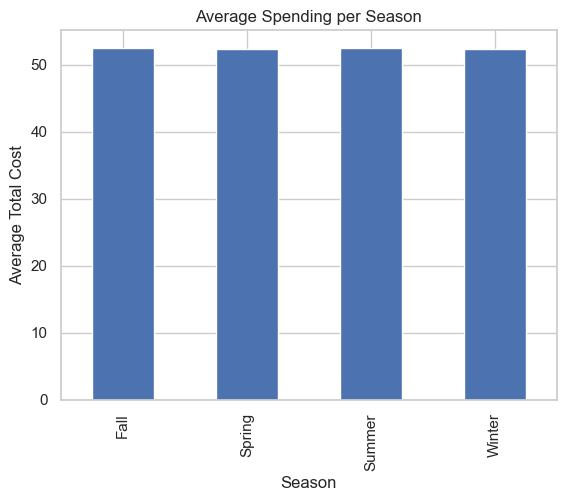

In [35]:
# Create a plot showing average spending per season.
avg_season_spend = df.groupby('Season')['Total_Cost'].mean()

plt.figure()
avg_season_spend.plot(kind='bar')
plt.title("Average Spending per Season")
plt.ylabel("Average Total Cost")
plt.show()

Average spending per transaction is nearly identical across all seasons.
Seasonality does not significantly impact individual transaction value in this dataset.

## Task 6: Visualisation Dashboard 

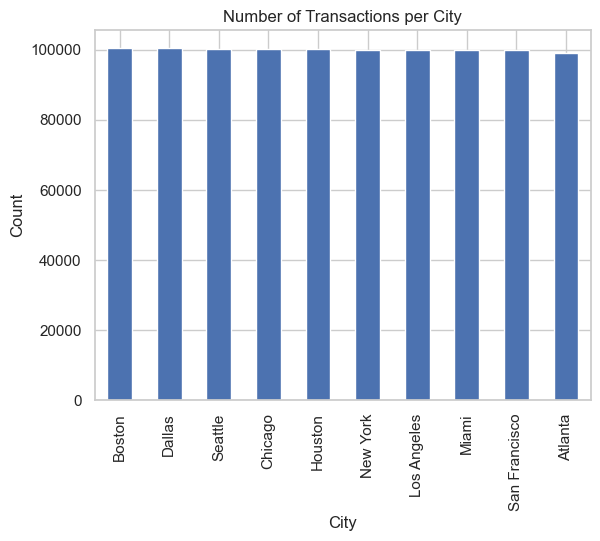

In [36]:
# Bar plot of the number of transactions per city
plt.figure()
df['City'].value_counts().plot(kind='bar')
plt.title("Number of Transactions per City")
plt.ylabel("Count")
plt.show()

Transactions are evenly distributed across all cities, with no city significantly outperforming others.
Geographic location does not appear to be a major driver of transaction volume in this dataset.

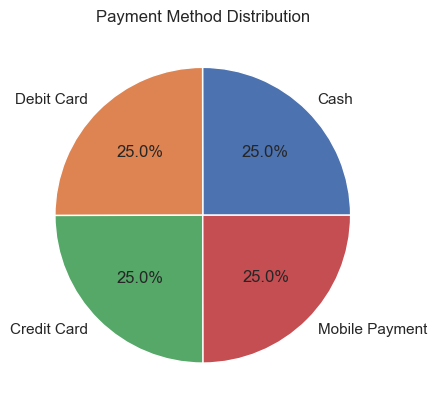

In [37]:
# Pie chart showing distribution of payment methods
df['Payment_Method'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title("Payment Method Distribution")
plt.ylabel("")
plt.show()

All payment methods contribute equally (25% each), indicating perfectly balanced usage.
No dominant payment preference exists across the customer base

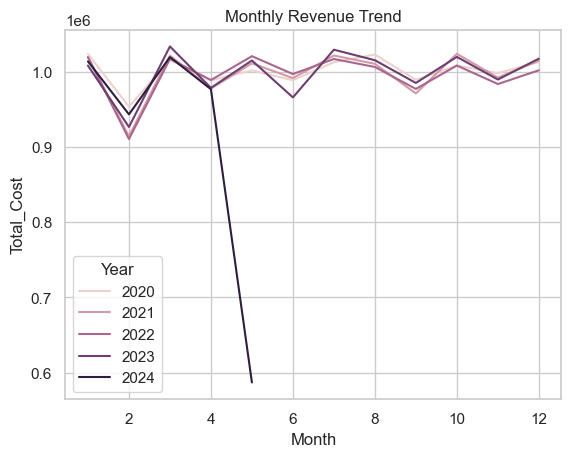

In [38]:
# Line chart of monthly revenue trends (grouped by year if applicable)
monthly_revenue = df.groupby(['Year', 'Month'])['Total_Cost'].sum().reset_index()

plt.figure()
sns.lineplot(data=monthly_revenue, x='Month', y='Total_Cost', hue='Year')
plt.title("Monthly Revenue Trend")
plt.show()

Revenue remains relatively stable across months and years, with minor fluctuations but no strong upward or downward trend.
The sharp drop in one year suggests incomplete data rather than a real revenue decline.

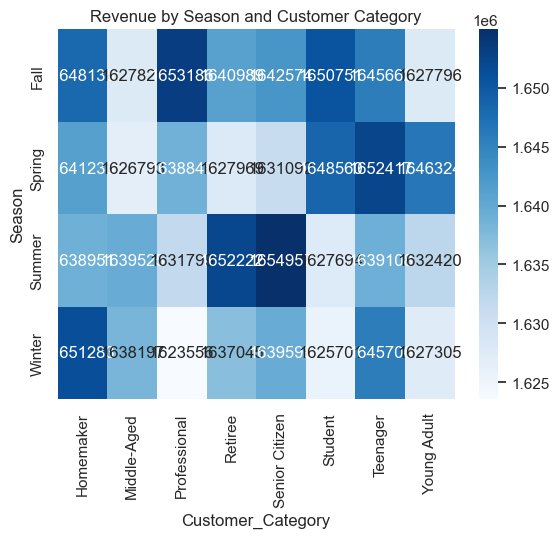

In [39]:
# Heatmap or stacked bar showing revenue by season and customer category 
season_category = df.pivot_table(
    values='Total_Cost',
    index='Season',
    columns='Customer_Category',
    aggfunc='sum'
)

plt.figure()
sns.heatmap(season_category, annot=True, fmt=".0f", cmap="Blues")
plt.title("Revenue by Season and Customer Category")
plt.show()

Revenue contribution across seasons and customer categories is highly uniform with no strong seasonal dominance.
Customer segments generate similar revenue levels regardless of season, indicating stable purchasing behavior year-round.